# Open Table Catalogs (Iceberg REST)

An Iceberg table is a tree of metadata files in object storage. Something must answer the question
"which metadata file is the **current** version of `taxi.trips`?" and must change that answer **atomically** when a
writer commits. That is the job of a **catalog**. The **Iceberg REST catalog** is an open HTTP API for this; Apache
Polaris, Nessie, Lakekeeper, Gravitino, Unity Catalog, AWS Glue and S3 Tables all implement it, so any engine that
speaks REST (Spark, Trino, Flink, Snowflake, DuckDB, PyIceberg) can share the same tables.

**After this lesson you can:**

1. Explain what a catalog does and why the REST specification matters.
2. Create namespaces and tables through the REST API and with PyIceberg, and read them from DuckDB.
3. See optimistic concurrency: how the catalog rejects a stale commit.
4. Use tags, branches (write-audit-publish) and partition evolution.

**Data:** NYC taxi trips, January 2024.
**Services:** RustFS (S3-compatible storage) + the Apache Iceberg REST reference catalog:
`docker compose -f docker/compose.yml --profile lakehouse up -d rustfs iceberg-rest` (catalog on http://localhost:8181).

In [1]:
import sys
import time
from pathlib import Path

import boto3
import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import pyarrow as pa
import requests
from pyiceberg.catalog import load_catalog
from pyiceberg.exceptions import CommitFailedException
from pyiceberg.partitioning import PartitionField, PartitionSpec
from pyiceberg.transforms import BucketTransform, DayTransform

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: pinned datasets and Docker services

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
datasets.ensure_service("lakehouse", "rustfs")
datasets.ensure_service("lakehouse", "iceberg-rest")
REST = "http://localhost:8181"
for _ in range(60):                               # the catalog needs a few seconds after the container starts
    try:
        requests.get(f"{REST}/v1/config", timeout=2).raise_for_status(); break
    except requests.RequestException:
        time.sleep(1)
s3 = boto3.client("s3", region_name="us-east-1", endpoint_url="http://localhost:9000",
                  aws_access_key_id="course", aws_secret_access_key="course-password")
if "lakehouse" not in [b["Name"] for b in s3.list_buckets()["Buckets"]]:
    s3.create_bucket(Bucket="lakehouse")

raw = pd.read_parquet(datasets.taxi("2024-01"), columns=["tpep_pickup_datetime", "PULocationID", "DOLocationID",
                                                         "trip_distance", "total_amount"])
raw = raw[(raw.tpep_pickup_datetime >= "2024-01-01") & (raw.tpep_pickup_datetime < "2024-01-09")].reset_index(drop=True)
raw["tpep_pickup_datetime"] = raw.tpep_pickup_datetime.dt.tz_localize("UTC").astype("datetime64[us, UTC]")
raw["PULocationID"] = raw.PULocationID.astype("int64"); raw["DOLocationID"] = raw.DOLocationID.astype("int64")
by_day = {str(d): pa.Table.from_pandas(g.reset_index(drop=True), preserve_index=False)
          for d, g in raw.groupby(raw.tpep_pickup_datetime.dt.date)}
print("catalog config:", requests.get(f"{REST}/v1/config", timeout=10).json())
print({d: t.num_rows for d, t in by_day.items()})

catalog config: {'defaults': {}, 'overrides': {}, 'endpoints': ['POST v1/oauth/tokens', 'POST https://auth-server.com/token', 'GET v1/config', 'GET /v1/{prefix}/namespaces', 'POST /v1/{prefix}/namespaces', 'HEAD /v1/{prefix}/namespaces/{namespace}', 'GET /v1/{prefix}/namespaces/{namespace}', 'DELETE /v1/{prefix}/namespaces/{namespace}', 'POST /v1/{prefix}/namespaces/{namespace}/properties', 'GET /v1/{prefix}/namespaces/{namespace}/tables', 'POST /v1/{prefix}/namespaces/{namespace}/tables', 'HEAD /v1/{prefix}/namespaces/{namespace}/tables/{table}', 'GET /v1/{prefix}/namespaces/{namespace}/tables/{table}', 'POST /v1/{prefix}/namespaces/{namespace}/register', 'POST /v1/{prefix}/namespaces/{namespace}/tables/{table}', 'DELETE /v1/{prefix}/namespaces/{namespace}/tables/{table}', 'POST /v1/{prefix}/tables/rename', 'POST /v1/{prefix}/namespaces/{namespace}/tables/{table}/metrics', 'POST /v1/{prefix}/transactions/commit', 'GET /v1/{prefix}/namespaces/{namespace}/views', 'HEAD /v1/{prefix}/name

## 1. The REST API Itself

The catalog is plain HTTP + JSON (OpenAPI spec `rest-catalog-open-api.yaml`). Namespaces group tables
(like database schemas).

In [2]:
# clean start: drop the lesson's tables and namespace from an earlier run
for t in requests.get(f"{REST}/v1/namespaces/taxi/tables", timeout=10).json().get("identifiers", []):
    requests.delete(f"{REST}/v1/namespaces/taxi/tables/{t['name']}?purgeRequested=true", timeout=30)
requests.delete(f"{REST}/v1/namespaces/taxi", timeout=10)

r = requests.post(f"{REST}/v1/namespaces", json={"namespace": ["taxi"], "properties": {"owner": "data-eng"}}, timeout=10)
print("POST /v1/namespaces ->", r.status_code, r.json())
print("GET  /v1/namespaces ->", requests.get(f"{REST}/v1/namespaces", timeout=10).json())

POST /v1/namespaces -> 200 {'namespace': ['taxi'], 'properties': {'owner': 'data-eng', 'location': 's3://lakehouse/warehouse/taxi'}}
GET  /v1/namespaces -> {'namespaces': [['taxi']], 'next-page-token': None}


## 2. Create and Fill a Table with PyIceberg

PyIceberg talks to the REST catalog and writes the data files and metadata to RustFS. The table is partitioned by
`day(tpep_pickup_datetime)` (hidden partitioning, see Lesson 04). Each daily load is one snapshot.

In [3]:
catalog = load_catalog("lake", **{"type": "rest", "uri": REST, "s3.endpoint": "http://localhost:9000",
                                  "s3.access-key-id": "course", "s3.secret-access-key": "course-password",
                                  "s3.region": "us-east-1", "s3.path-style-access": "true"})
schema_tbl = catalog.create_table("taxi.schema_probe", schema=by_day["2024-01-01"].schema)   # assigns field IDs
schema = schema_tbl.schema(); catalog.drop_table("taxi.schema_probe")
spec = PartitionSpec(PartitionField(source_id=schema.find_field("tpep_pickup_datetime").field_id, field_id=1000,
                                    transform=DayTransform(), name="pickup_day"))
trips = catalog.create_table("taxi.trips", schema=schema, partition_spec=spec,
                             properties={"write.parquet.compression-codec": "zstd"})
for d in list(by_day)[:7]:
    trips.append(by_day[d])

print("table location:", trips.location())
print("metadata file: ", trips.metadata_location.split("/")[-1])
snaps = pd.DataFrame([{"snapshot_id": s.snapshot_id, "operation": s.summary.operation.value,
                       "added_records": int(s.summary["added-records"]), "total_records": int(s.summary["total-records"])}
                      for s in trips.snapshots()])
print(snaps.to_string(index=False))

table location: s3://lakehouse/warehouse/taxi/trips
metadata file:  00007-4022a5c4-a5cd-4462-8706-7dbf9ee0d955.metadata.json
        snapshot_id operation  added_records  total_records
6896222866036363111    append          81013          81013
1365986281469133962    append          75519         156532
7924409697470852749    append          82427         238959
6458220160338415071    append         102901         341860
3517936126368330166    append         103178         445038
4261443277335522688    append          97117         542155
1823357884982624565    append          67543         609698


## 3. A Second Engine: DuckDB Reads the Same Table

DuckDB's `iceberg` extension can attach a REST catalog. Nothing is copied: DuckDB asks the catalog for the current
metadata file and reads the Parquet files from RustFS.

In [4]:
con = duckdb.connect()
con.execute("SET enable_progress_bar = false")
con.execute("INSTALL iceberg; LOAD iceberg; INSTALL httpfs; LOAD httpfs")
con.execute("""CREATE SECRET lake_s3 (TYPE s3, KEY_ID 'course', SECRET 'course-password', REGION 'us-east-1',
                 ENDPOINT 'localhost:9000', URL_STYLE 'path', USE_SSL false)""")
con.execute("SET TimeZone = 'UTC'")      # the column is timestamptz: CAST(... AS DATE) uses the session time zone
con.execute("ATTACH '' AS lake (TYPE iceberg, ENDPOINT 'http://localhost:8181', AUTHORIZATION_TYPE 'none')")
daily = con.execute("""
    SELECT CAST(tpep_pickup_datetime AS DATE) AS day, count(*) AS trips, round(sum(total_amount)) AS revenue
    FROM lake.taxi.trips GROUP BY 1 ORDER BY 1""").df()
print(daily.to_string(index=False))

       day  trips   revenue
2024-01-01  81013 2442843.0
2024-01-02  75519 2282196.0
2024-01-03  82427 2357588.0
2024-01-04 102901 2800511.0
2024-01-05 103178 2728673.0
2024-01-06  97117 2436272.0
2024-01-07  67543 1898102.0


## 4. Optimistic Concurrency: the Catalog Decides

Two writers load the table at the same version and both try to commit. Each commit says "I expect the current
snapshot to be X". The catalog accepts the first and **rejects** the second, because X is no longer current;
the second writer must refresh and retry. This compare-and-swap is what makes concurrent writes safe.

In [5]:
writer_a = catalog.load_table("taxi.trips")
writer_b = catalog.load_table("taxi.trips")        # same starting snapshot as writer A
day8 = by_day["2024-01-08"]
half = day8.num_rows // 2

writer_a.append(day8.slice(0, half))
print("writer A committed; current snapshot:", catalog.load_table("taxi.trips").current_snapshot().snapshot_id)
try:
    with writer_b.transaction() as tx:              # stale metadata: B still thinks the old snapshot is current
        tx.append(day8.slice(half))
    print("writer B committed (PyIceberg refreshed and retried automatically)")
except CommitFailedException as e:
    print("writer B rejected:", str(e).splitlines()[0][:120])
    writer_b.refresh()
    writer_b.append(day8.slice(half))
    print("writer B refreshed and retried -> committed")
trips.refresh()
print("rows now:", trips.scan().count(), "| expected:", sum(t.num_rows for t in by_day.values()))

Commit failed due to a concurrent update, retrying (1/4) in 102 ms


writer A committed; current snapshot: 443208008530423319


writer B committed (PyIceberg refreshed and retried automatically)
rows now: 689732 | expected: 689732


## 5. Tags and Branches

- A **tag** is a named, immutable snapshot (e.g. `month-end-close`), kept even when old snapshots expire.
- A **branch** is a named line of snapshots. **Write-audit-publish (WAP):** write new data to a branch, run quality
  checks on the branch, and publish only if they pass by moving `main` to the branch head. Readers of `main` never
  see unchecked data.

In [6]:
week1 = [s for s in trips.snapshots() if int(s.summary["total-records"]) == sum(by_day[d].num_rows for d in list(by_day)[:7])][0]
trips.manage_snapshots().create_tag(week1.snapshot_id, "week-1-close").commit()
trips.manage_snapshots().create_branch(trips.current_snapshot().snapshot_id, "audit").commit()

# a bad delivery: duplicated rows and negative totals, written to the audit branch only
bad = pa.concat_tables([by_day["2024-01-08"].slice(0, 5000)] * 2)
bad = bad.set_column(bad.schema.get_field_index("total_amount"), "total_amount",
                     pa.array([-abs(x) for x in bad["total_amount"].to_pylist()]))
trips.append(bad, branch="audit")
trips.refresh()

def audit(snapshot_id: int) -> dict:
    df = trips.scan(snapshot_id=snapshot_id, selected_fields=("total_amount",)).to_pandas()
    return {"rows": len(df), "negative_totals": int((df.total_amount < 0).sum())}

main_id = trips.current_snapshot().snapshot_id
audit_id = trips.snapshot_by_name("audit").snapshot_id
print("main :", audit(main_id))
print("audit:", audit(audit_id))
ok = audit(audit_id)["negative_totals"] == 0
print("publish audit -> main?", ok)
if ok:
    trips.manage_snapshots().set_current_snapshot(snapshot_id=audit_id).commit()
trips.refresh()
print("main after the decision:", audit(trips.current_snapshot().snapshot_id))
print("refs:", {name: ref.snapshot_ref_type.value for name, ref in trips.refs().items()})
print("tag week-1-close still readable:", trips.scan(snapshot_id=trips.snapshot_by_name('week-1-close').snapshot_id).count(), "rows")

main : {'rows': 689732, 'negative_totals': 9221}
audit: {'rows': 699732, 'negative_totals': 19221}
publish audit -> main? False


main after the decision: {'rows': 689732, 'negative_totals': 9221}
refs: {'main': 'branch', 'week-1-close': 'tag', 'audit': 'branch'}
tag week-1-close still readable: 609698 rows


*Insight: Branches give a lakehouse the same safety as a code review: new data lands on a side branch, checks run, and only a fast-forward makes it visible. The bad delivery above never reached readers of `main`.*

## 6. Partition Evolution

Partitioning by day was right for one month; after years of data, analysts filter by zone too. Iceberg can **add a
partition field** to the spec. Old files keep the old layout, new files use the new one, and queries work across
both, with no rewrite.

partition specs: {0: ['pickup_day'], 1: ['pickup_day', 'zone_bucket']}
data files by spec id: {0: 9, 1: 8}
files planned for PULocationID == 132: 10 of 17


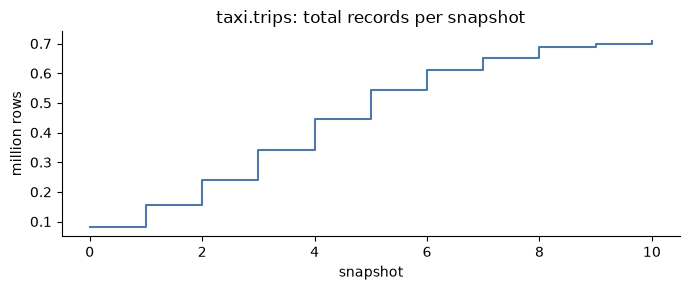

In [7]:
with trips.update_spec() as u:
    u.add_field("PULocationID", BucketTransform(8), "zone_bucket")
extra = pa.Table.from_pandas(raw[raw.tpep_pickup_datetime.dt.day == 8].head(20_000).reset_index(drop=True), preserve_index=False)
trips.append(extra)
trips.refresh()
files = list(trips.scan().plan_files())
per_spec = pd.Series([f.file.spec_id for f in files]).value_counts().sort_index()
print("partition specs:", {s.spec_id: [f.name for f in s.fields] for s in trips.specs().values()})
print("data files by spec id:", per_spec.to_dict())
zone_files = list(trips.scan(row_filter="PULocationID == 132").plan_files())
print(f"files planned for PULocationID == 132: {len(zone_files)} of {len(files)}")

fig, ax = plt.subplots(figsize=(7, 3))
snap = pd.DataFrame([{"n": i, "records": int(s.summary["total-records"])} for i, s in enumerate(trips.snapshots())])
ax.step(snap.n, snap.records / 1e6, where="post", color="#4E79A7")
ax.set(title="taxi.trips: total records per snapshot", xlabel="snapshot", ylabel="million rows")
plt.tight_layout(); plt.show()

*Insight: A shared REST catalog is the "single source of truth" of a lakehouse: every engine commits through it, it enforces atomic swaps, and it is where access control and governance (Polaris, Unity Catalog, Lakekeeper) plug in.*

## Real-World Use Case or Analogy

A REST catalog is like a **land registry**. The houses (data files) and the deeds (metadata) exist on their own,
but the registry records which deed is current, accepts a new deed only if the seller still owns the house
(optimistic concurrency), and every bank, lawyer and buyer (engine) checks the same registry.

Companies that run Spark for ETL, Trino or DuckDB for analysts, Flink for streaming and Snowflake for BI point all of
them at one Iceberg REST catalog, so there is one copy of each table instead of one copy per tool.